# Copper price forecasting: Replication of results from Liu (2017) and + Díaz et al.

This notebook has **three separate experiments**:

1. **Liu et al. (2017)-style replication attempt** on the paper's 2008–2015 sample, using the eight price series, a decision tree, the paper's lag parameter `D`, forecast-distance parameter `G`, and rolling-origin forecasts.

2. **Diaz et al. (2020)-style replication attempt** on the paper's 2008–2015 sample and 2008-2020 sample, using the same eight price series as Liu, a regression tree, a random forest, a gradient boosting regression tree, and a random walk model. The paper uses the same lag parameter `D`, forecast-distance parameter `G`, and rolling-origin forecasts.

3. **Modern model comparison** on the available 2008–2026 data, comparing regression tree, random forest, gradient boosting, optional XGBoost, and a random-walk benchmark on a chronological held-out period.

**NOTE:** This is a *replication attempt* of these papers' results to see if these models will work on the provided data sets. The same-ish code will be applied to the lithium market, but with lithium centered data. In addition, machine learning will be applied to supply and demand data to develop a market balance prediction model. this will be used to help aid in lithium price predictions. I have yet to find a paper that does this for lithium price. One paper by Li et al. states: "This paper is a pure time series forecasting model based on past historical data. It does not capture lithium price fluctuations' underlying structural or economic drivers. Future research could specifically look at the drivers of lithium prices from a machine learning perspective by bringing different dimensions such impact of electric vehicle demand, the role of manufacturers of lithium-ion batteries, industry-dependent structural changes in the economy, etc....since this is one of the first few attempts at modeling the time series lithium prices through machine learning methods, our paper does not capture and compare forecasting accuracy across varied methodological choices."

**ANOTHER NOTE:** I used ChatGPT to help generate the base code of this noetbook, but then further edited it to ensure it worked correctly and to add in analyis it failed to include


## 1. Imports and settings

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import matplotlib.dates as mdates

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
BASE = Path.cwd()
OUT = BASE / "copper_forecasting_outputs"
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "Copper": "Copper Futures Historical Data(2).csv",
    "Gold": "Gold Futures Historical Data(2).csv",
    "Silver": "Silver Futures Historical Data(2).csv",
    "Oil": "Crude Oil WTI Futures Historical Data(2).csv",
    "Gas": "Natural Gas Futures Historical Data(2).csv",
    "Lean Hogs": "Lean Hogs Futures Historical Data(2).csv",
    "Coffee": "US Coffee C Futures Historical Data(2).csv",
    "Dow Jones": "Dow Jones Industrial Average Historical Data(2).csv",
}

try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("xgboost is not installed; XGBoost will be skipped without stopping the notebook.")

## 2. Liu et al. (2017): paper-period data and rolling-origin decision tree

The paper reports data from **January 3, 2008 through December 1, 2015**. We filter the common-date dataset to that period. For each forecast origin `t`, predictors contain the latest `D` observations of all eight variables, including the observation at `t`. Following the paper's described construction, historical training pairs map each feature window to copper's price on that historical day; the fitted tree is then applied at the forecast origin and its prediction is compared with copper `G+1` observations later. This is a **paper-inspired replication of the published procedure**, not a standard horizon-shifted supervised forecasting setup.

The paper's plot uses `D=10` and `G = 0, 5, 30, 120, 180, 360, 720, 1080`. For runtime, forecasts are generated every 30 observations by default; set `PLOT_EVERY = 1` for denser predictions. The paper's source data preprocessing and exact observations may differ from the newly downloaded CSVs, so exact numerical reproduction is not guaranteed.

In [2]:
# Folder containing the eight Investing.com CSV files
DATA_DIR = Path(".")
OUT = Path("liu_replication_outputs")
OUT.mkdir(parents=True, exist_ok=True)

# Liu et al. (2017) study period
START_DATE = "2008-01-03"
END_DATE = "2015-12-01"

# Create a date index containing weekdays only.
# Weekdays on which markets were closed will be interpolated.
weekday_dates = pd.bdate_range(
    start=START_DATE,
    end=END_DATE,
    name="Date")

# CSV filenames and corresponding variable names
files = {
    "Copper": "Copper Futures Historical Data(2).csv",
    "Gold": "Gold Futures Historical Data(2).csv",
    "Silver": "Silver Futures Historical Data(2).csv",
    "Crude_Oil": "Crude Oil WTI Futures Historical Data(2).csv",
    "Natural_Gas": "Natural Gas Futures Historical Data(2).csv",
    "Lean_Hogs": "Lean Hogs Futures Historical Data(2).csv",
    "Coffee": "US Coffee C Futures Historical Data(2).csv",
    "Dow_Jones": "Dow Jones Industrial Average Historical Data(2).csv",
}

processed_series = {}
audit_rows = []

for variable, filename in files.items():
    # Load raw market data
    df = pd.read_csv(DATA_DIR / filename)
    
    # Parse dates and convert prices to numeric values.
    # Removing commas is necessary for Dow Jones prices.
    df["Date"] = pd.to_datetime(
        df["Date"],
        format="%m/%d/%Y",
        errors="coerce")
    df["Price"] = pd.to_numeric(
        df["Price"].astype(str).str.replace(",", "", regex=False),
        errors="coerce")
    
    # Restrict the data to Liu et al.'s date range
    df = df.dropna(subset=["Date", "Price"])
    df = df.loc[df["Date"].between(START_DATE, END_DATE)]
    
    # One price per date, ordered chronologically
    prices = (
        df.groupby("Date")["Price"]
        .mean()
        .sort_index())
    
    # Reindex to all weekdays, introducing NaN on missing weekdays
    prices_weekdays = prices.reindex(weekday_dates)
    missing_before = int(prices_weekdays.isna().sum())
    
    # Linear interpolation:
    # For a single missing weekday, this equals: (previous observed price + next observed price) / 2.
    # For consecutive missing weekdays, it interpolates between the nearest available observations.
    prices_filled = prices_weekdays.interpolate(
        method="linear",
        limit_area="inside")
    
    missing_after = int(prices_filled.isna().sum())
    values_filled = missing_before - missing_after
    processed_series[variable] = prices_filled
    audit_rows.append({
        "Variable": variable,
        "Observed_prices": int(prices_weekdays.notna().sum()),
        "Missing_before_interpolation": missing_before,
        "Values_interpolated": values_filled,
        "Missing_after_interpolation": missing_after
    })

# Combine all eight processed series into one dataset
data = pd.DataFrame(processed_series, index=weekday_dates)
data.index.name = "Date"

# Check for missing values that interpolation could not fill
audit = pd.DataFrame(audit_rows).set_index("Variable")

print("Date range:", data.index.min().date(),
      "through", data.index.max().date())
print("Number of weekday observations:", len(data))
print("Total missing values remaining:", int(data.isna().sum().sum()))

display(audit)
display(data.head())

# Save the processed dataset and interpolation audit
data.to_csv(OUT / "liu_2008_2015_interpolated_data.csv")
audit.to_csv(OUT / "liu_interpolation_audit.csv")


Date range: 2008-01-03 through 2015-12-01
Number of weekday observations: 2064
Total missing values remaining: 0


,Observed_prices,Missing_before_interpolation,Values_interpolated,Missing_after_interpolation
Variable,,,,
Copper,1996,68,68,0
Gold,1997,67,67,0
Silver,2039,25,25,0
Crude_Oil,2015,49,49,0
Natural_Gas,2015,49,49,0
Lean_Hogs,2011,53,53,0
Coffee,2011,53,53,0
Dow_Jones,2033,31,31,0


,Copper,Gold,Silver,Crude_Oil,Natural_Gas,Lean_Hogs,Coffee,Dow_Jones
Date,,,,,,,,
2008-01-03,3.1880,869.1,15.500,99.18,7.674,56.48,135.20,13056.72
2008-01-04,3.1575,865.7,15.462,97.91,7.841,56.40,132.70,12800.18
2008-01-07,3.1410,862.0,15.290,95.09,7.879,55.70,131.40,12827.49
2008-01-08,3.2985,880.3,15.815,96.33,7.967,55.88,135.45,12589.07
2008-01-09,3.2835,881.7,15.840,95.67,8.099,56.52,135.60,12735.31


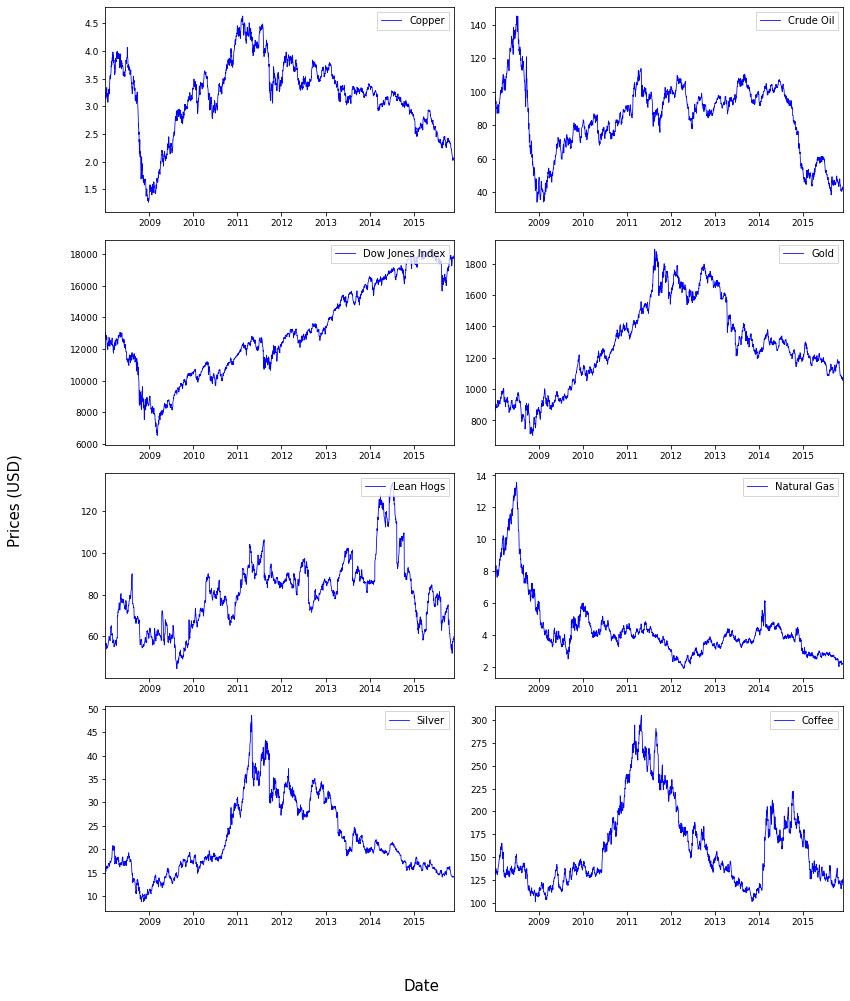

Figure saved to: liu_replication_outputs/liu_figure1_actual_prices.png


In [3]:
# Match the arrangement of Liu et al. (2017), Figure 1
plot_specs = [
    ("Copper", "Copper"),
    ("Crude_Oil", "Crude Oil"),
    ("Dow_Jones", "Dow Jones Index"),
    ("Gold", "Gold"),
    ("Lean_Hogs", "Lean Hogs"),
    ("Natural_Gas", "Natural Gas"),
    ("Silver", "Silver"),
    ("Coffee", "Coffee"),
]

# Check that all required columns exist
missing_columns = [
    column for column, label in plot_specs
    if column not in data.columns
]
if missing_columns:
    raise ValueError(
        f"Missing columns in data: {missing_columns}"
    )

# Keep the date range used in Liu et al. (2017)
plot_data = data.loc["2008-01-03":"2015-12-01"].copy()

# Create a 4 x 2 grid
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 14)
)

# Draw each market's price series
for ax, (column, label) in zip(axes.flat, plot_specs):
    series = plot_data[column].dropna()
    ax.plot(
        series.index,
        series.values,
        color="blue",
        linewidth=0.8,
        label=label)
    # Legend inside each subplot, similar to the paper
    ax.legend(
        loc="upper right",
        frameon=True,
        fancybox=False,
        fontsize=10)
    # Show calendar years on the x-axis
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(
        axis="x",
        labelsize=9,
        rotation=0)
    ax.tick_params(
        axis="y",
        labelsize=9)
    # Match the clean appearance of the paper
    ax.grid(False)
    ax.set_xlim(
        pd.Timestamp("2008-01-03"),
        pd.Timestamp("2015-12-01"))

# Shared axis labels
fig.supylabel("Prices (USD)", fontsize=15)
fig.supxlabel("Date", fontsize=15)

# Adjust subplot spacing
fig.tight_layout(rect=[0.05, 0.04, 1, 1])

# Save a high-resolution version
output_file = OUT / "liu_figure1_actual_prices.png"
fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight")

plt.show()

print(f"Figure saved to: {output_file}")


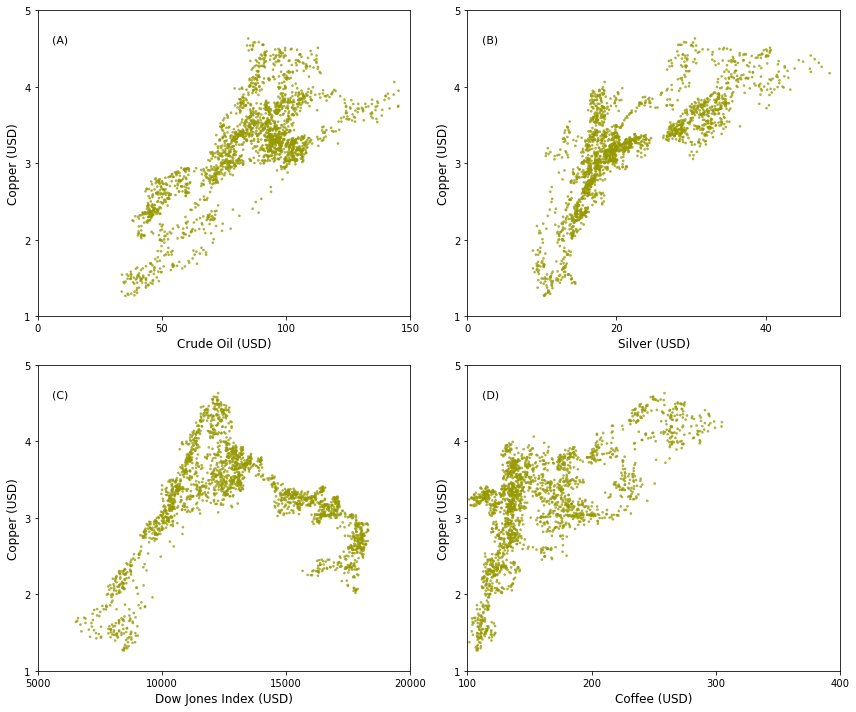

Figure saved to: liu_replication_outputs/liu_figure2_copper_scatter_plots.png


In [4]:

# Figure 2 panels: (x variable, x-axis label, panel label)
scatter_specs = [
    ("Crude_Oil", "Crude Oil (USD)", "(A)"),
    ("Silver", "Silver (USD)", "(B)"),
    ("Dow_Jones", "Dow Jones Index (USD)", "(C)"),
    ("Coffee", "Coffee (USD)", "(D)")
]

# Set up the 2 x 2 figure
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12, 10)
)

# Olive-green dots, similar to Liu et al.'s figure
point_color = "#969900"

for ax, (x_col, x_label, panel_label) in zip(
    axes.flat, scatter_specs
):
    # Same-day copper price and explanatory variable
    plot_df = plot_data[[x_col, "Copper"]].dropna()

    ax.scatter(
        plot_df[x_col],
        plot_df["Copper"],
        s=7,
        color=point_color,
        alpha=0.75,
        edgecolors="none"
    )

    # Axis labels
    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel("Copper (USD)", fontsize=12)

    # Panel labels, placed inside the upper-left corner
    ax.text(
        0.04, 0.92,
        panel_label,
        transform=ax.transAxes,
        fontsize=11,
        verticalalignment="top"
    )

    ax.tick_params(axis="both", labelsize=10)
    ax.grid(False)

    # Match the approximate ranges shown in the published figure
    if x_col == "Crude_Oil":
        ax.set_xlim(0, 150)
        ax.set_xticks([0, 50, 100, 150])

    elif x_col == "Silver":
        ax.set_xlim(0, 50)
        ax.set_xticks([0, 20, 40])

    elif x_col == "Dow_Jones":
        ax.set_xlim(5000, 20000)
        ax.set_xticks([5000, 10000, 15000, 20000])

    elif x_col == "Coffee":
        ax.set_xlim(100, 400)
        ax.set_xticks([100, 200, 300, 400])

    ax.set_ylim(1, 5)
    ax.set_yticks([1, 2, 3, 4, 5])

# Spacing between panels
fig.tight_layout()

# Save the figure
output_file = OUT / "liu_figure2_copper_scatter_plots.png"
fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {output_file}")


Gold           0.599426
Silver         0.767258
Crude_Oil      0.751137
Natural_Gas    0.129353
Lean_Hogs      0.401114
Coffee         0.647717
Dow_Jones      0.077448
Name: Copper, dtype: float64

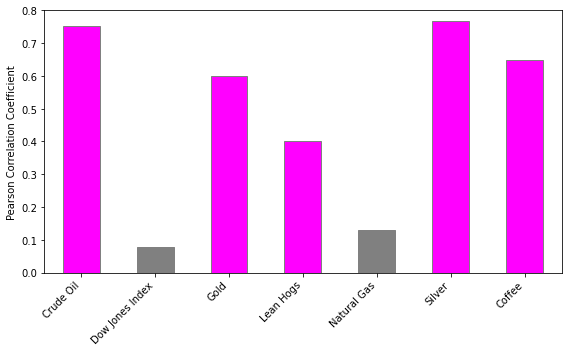

In [5]:

# Calculate correlations with copper
copper_correlations = data.corr()["Copper"].drop("Copper")
display(copper_correlations)

# Plot the correlations in Liu's Figure 3 order
copper_correlations = copper_correlations.reindex([
    "Crude_Oil", "Dow_Jones", "Gold", "Lean_Hogs",
    "Natural_Gas", "Silver", "Coffee"
])

copper_correlations.index = [
    "Crude Oil", "Dow Jones Index", "Gold", "Lean Hogs",
    "Natural Gas", "Silver", "Coffee"
]

# Color weak correlations gray and the others magenta
colors = [
    "gray" if abs(value) < 0.2 else "magenta"
    for value in copper_correlations
]

copper_correlations.plot(
    kind="bar",
    color=colors,
    edgecolor="gray",
    figsize=(8, 5)
)

plt.ylabel("Pearson Correlation Coefficient")
plt.ylim(0, 0.8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [6]:
paper_data = data.loc["2008-01-03":"2015-12-01"].copy()
print(paper_data.columns.tolist())

['Copper', 'Gold', 'Silver', 'Crude_Oil', 'Natural_Gas', 'Lean_Hogs', 'Coffee', 'Dow_Jones']


Liu et al. paper-period data
Observations: 2,064
Dates: 2008-01-03 through 2015-12-01
Variables: ['Crude_Oil', 'Copper', 'Gold', 'Silver', 'Natural_Gas', 'Coffee', 'Dow_Jones', 'Lean_Hogs']
Minimum initial training rows: 607
Forecast-origin step: 10

Processing D = 1
  Forecast horizon G = 0
    Forecasts: 146, MAPE: 1.41%
  Forecast horizon G = 5
    Forecasts: 145, MAPE: 3.60%
  Forecast horizon G = 30
    Forecasts: 140, MAPE: 8.33%
  Forecast horizon G = 120
    Forecasts: 122, MAPE: 12.64%
  Forecast horizon G = 180
    Forecasts: 110, MAPE: 22.16%
  Forecast horizon G = 360
    Forecasts: 74, MAPE: 20.58%
  Forecast horizon G = 720
    Forecasts: 2, MAPE: 73.68%
  Forecast horizon G = 1080
    No eligible out-of-sample forecasts for this horizon and training requirement.

Processing D = 10
  Forecast horizon G = 0
    Forecasts: 145, MAPE: 1.50%
  Forecast horizon G = 5
    Forecasts: 144, MAPE: 3.53%
  Forecast horizon G = 30
    Forecasts: 139, MAPE: 8.88%
  Forecast horizon G 

,D,G,ForecastDistance,N_predictions,MAPE_percent,RMS_percent,Outliers_over_10_percent
0,1,0,1,146,1.41,1.90,0.00
1,1,5,6,145,3.60,4.89,4.83
2,1,30,31,140,8.33,10.90,30.00
3,1,120,121,122,12.64,15.30,61.48
4,1,180,181,110,22.16,25.23,80.00
5,1,360,361,74,20.58,23.88,87.84
6,1,720,721,2,73.68,74.06,100.00
7,1,1080,1081,0,NaN,NaN,NaN
8,10,0,1,145,1.50,2.25,0.00
9,10,5,6,144,3.53,4.76,4.86


Saved predictions and metrics.


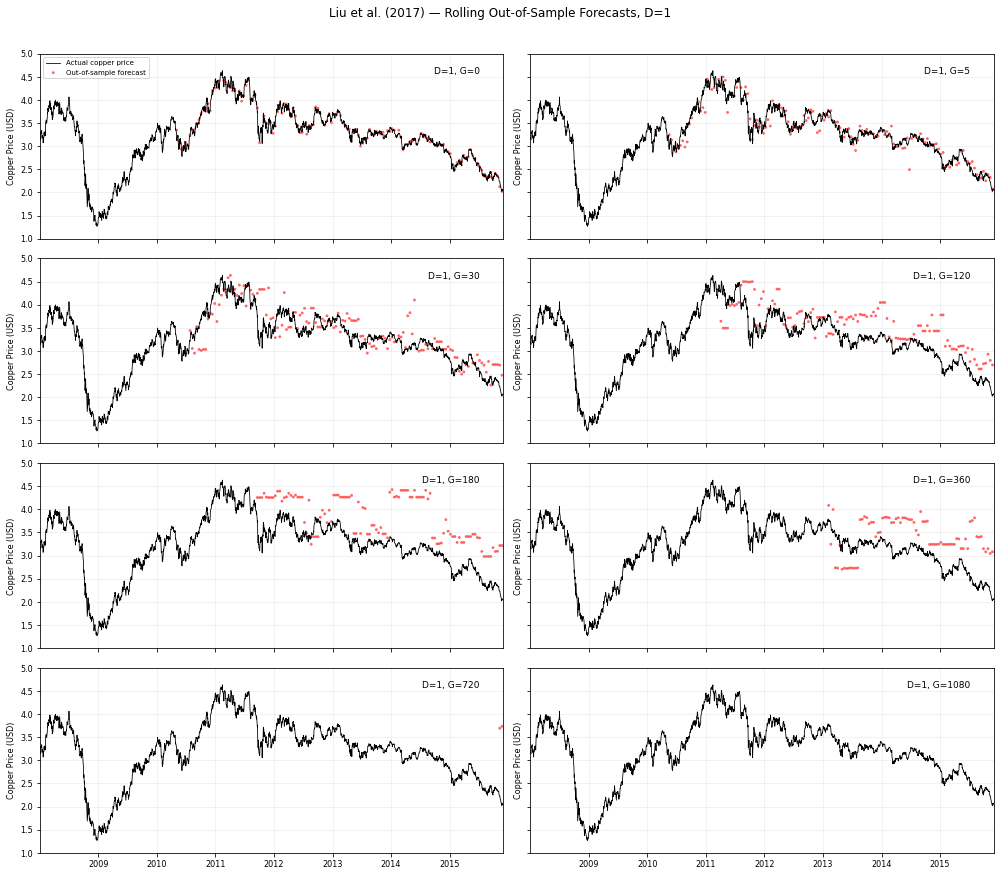

Saved Figure 7: liu_replication_outputs/liu_figure7_D1.png


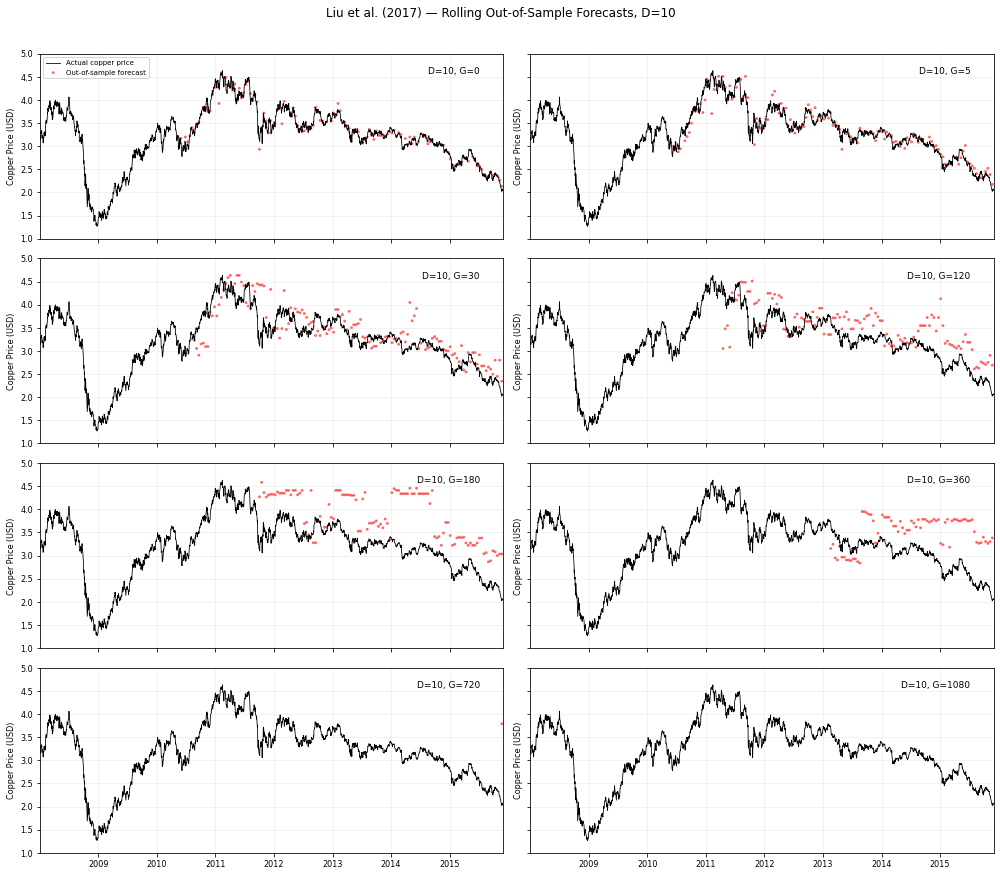

Saved Figure 8: liu_replication_outputs/liu_figure8_D10.png

Finished.
Results folder: /home/schmidlucy/Lucy-Schmid.github.io/notebooks/Term Project/diaz replication new/liu_replication_outputs


In [7]:

D_VALUES = [1, 10]

G_VALUES = [0, 5, 30, 120, 180, 360, 720, 1080]

# Liu's example uses 607 training observations.
MIN_TRAIN_ROWS = 607

# Run every 10th forecast origin to reduce runtime.
# Change to 1 to evaluate every eligible forecast origin.
PLOT_EVERY = 10

RANDOM_STATE = 42
TREE_MAX_DEPTH = 23

PAPER_START = pd.Timestamp("2008-01-03")
PAPER_END = pd.Timestamp("2015-12-01")


# ------------------------------------------------------------
# 2. CHECK AND PREPARE paper_data
# ------------------------------------------------------------

if "paper_data" not in globals():
    raise NameError(
        "paper_data was not found. Run your existing data-cleaning "
        "cell first."
    )

paper_data = paper_data.copy()

# Make sure the index contains dates.
if not isinstance(paper_data.index, pd.DatetimeIndex):

    if "Date" in paper_data.columns:
        paper_data["Date"] = pd.to_datetime(
            paper_data["Date"],
            errors="coerce"
        )
        paper_data = paper_data.set_index("Date")
    else:
        raise ValueError(
            "paper_data needs a DatetimeIndex or a Date column."
        )

paper_data = paper_data.sort_index()

# Accommodate common naming conventions without reloading files.
rename_options = {
    "Crude_Oil": ["Crude_Oil", "Crude Oil", "Oil"],
    "Copper": ["Copper"],
    "Gold": ["Gold"],
    "Silver": ["Silver"],
    "Natural_Gas": ["Natural_Gas", "Natural Gas", "Gas"],
    "Coffee": ["Coffee"],
    "Dow_Jones": ["Dow_Jones", "Dow Jones"],
    "Lean_Hogs": ["Lean_Hogs", "Lean Hogs"]
}

rename_map = {}

for desired_name, possible_names in rename_options.items():

    if desired_name in paper_data.columns:
        continue

    for possible_name in possible_names:

        if possible_name in paper_data.columns:
            rename_map[possible_name] = desired_name
            break

paper_data = paper_data.rename(columns=rename_map)

variables = [
    "Crude_Oil",
    "Copper",
    "Gold",
    "Silver",
    "Natural_Gas",
    "Coffee",
    "Dow_Jones",
    "Lean_Hogs"
]

missing = [
    name for name in variables
    if name not in paper_data.columns
]

if missing:
    raise ValueError(
        f"paper_data is missing columns: {missing}\n"
        f"Available columns: {paper_data.columns.tolist()}"
    )

paper_data = paper_data.loc[
    PAPER_START:PAPER_END,
    variables
].copy()

paper_data = paper_data.apply(
    pd.to_numeric,
    errors="coerce"
).dropna()

if paper_data.empty:
    raise ValueError(
        "No observations remain in the paper period. "
        "Check your dates and data columns."
    )

values = paper_data[variables].to_numpy(dtype=float)
copper = paper_data["Copper"].to_numpy(dtype=float)
dates = paper_data.index
n = len(paper_data)

print("Liu et al. paper-period data")
print(f"Observations: {n:,}")
print(f"Dates: {dates.min().date()} through {dates.max().date()}")
print(f"Variables: {variables}")
print(f"Minimum initial training rows: {MIN_TRAIN_ROWS}")
print(f"Forecast-origin step: {PLOT_EVERY}")


# ------------------------------------------------------------
# 3. GENERATE GENUINE OUT-OF-SAMPLE FORECASTS
# ------------------------------------------------------------

all_predictions = []
all_metrics = []

for D in D_VALUES:

    print(f"\nProcessing D = {D}")

    for G in G_VALUES:

        print(f"  Forecast horizon G = {G}")

        X_list = []
        y_list = []
        target_positions_list = []

        # For each historical target date s:
        #
        # Predictors: observations from s-G-D through s-G-1
        # Target:     copper price at s
        #
        # Thus, the prediction target is G+1 observations
        # after the latest predictor observation.

        for target in range(G + D, n):

            start = target - G - D
            end = target - G

            X_list.append(
                values[start:end, :].reshape(-1)
            )

            y_list.append(copper[target])
            target_positions_list.append(target)

        X_all = np.asarray(X_list, dtype=float)
        y_all = np.asarray(y_list, dtype=float)

        target_positions = np.asarray(
            target_positions_list,
            dtype=int
        )

        # A 607-row initial training sample is required.
        if len(y_all) < MIN_TRAIN_ROWS:

            all_metrics.append({
                "D": D,
                "G": G,
                "ForecastDistance": G + 1,
                "N_predictions": 0,
                "MAPE_percent": np.nan,
                "RMS_percent": np.nan,
                "Outliers_over_10_percent": np.nan
            })

            print("    Not enough observations for initial training.")
            continue

        # First origin at which 607 historical target values
        # are available. The model's training window then expands.
        first_origin = int(
            target_positions[MIN_TRAIN_ROWS - 1]
        )

        # To evaluate the forecast, its future target must exist
        # in the dataset: origin + G + 1 < n.
        last_origin = n - G - 2

        if first_origin > last_origin:

            all_metrics.append({
                "D": D,
                "G": G,
                "ForecastDistance": G + 1,
                "N_predictions": 0,
                "MAPE_percent": np.nan,
                "RMS_percent": np.nan,
                "Outliers_over_10_percent": np.nan
            })

            print(
                "    No eligible out-of-sample forecasts for "
                "this horizon and training requirement."
            )
            continue

        forecast_origins = np.arange(
            first_origin,
            last_origin + 1,
            PLOT_EVERY
        )

        predictions_for_case = []

        for origin in forecast_origins:

            # Only use training targets whose actual copper prices
            # were observable by the forecast origin.
            train_end = np.searchsorted(
                target_positions,
                origin,
                side="right"
            )

            if train_end < MIN_TRAIN_ROWS:
                continue

            X_train = X_all[:train_end]
            y_train = y_all[:train_end]

            # Future target is G+1 observations beyond the origin.
            target = int(origin + G + 1)

            # Match the feature window to this future target.
            test_row = int(
                target - target_positions[0]
            )

            if test_row < 0 or test_row >= len(X_all):
                continue

            X_test = X_all[test_row].reshape(1, -1)

            # Fit only on historical training observations.
            model = DecisionTreeRegressor(
                max_depth=TREE_MAX_DEPTH,
                random_state=RANDOM_STATE
            )

            model.fit(X_train, y_train)

            predicted = float(model.predict(X_test)[0])
            actual = float(copper[target])

            percentage_error = (
                (predicted - actual)
                / max(abs(actual), 1e-12)
            ) * 100

            predictions_for_case.append({
                "D": D,
                "G": G,
                "OriginDate": dates[origin],
                "TargetDate": dates[target],
                "OriginPosition": origin,
                "TargetPosition": target,
                "Actual": actual,
                "Prediction": predicted,
                "PercentageError": percentage_error,
                "TrainingRows": train_end
            })

        case_df = pd.DataFrame(predictions_for_case)

        if not case_df.empty:

            all_predictions.append(case_df)

            err = case_df["PercentageError"].to_numpy()

            mape = np.mean(np.abs(err))
            rms_percent = np.sqrt(np.mean(err ** 2))
            outlier_pct = np.mean(np.abs(err) > 10) * 100

        else:
            mape = np.nan
            rms_percent = np.nan
            outlier_pct = np.nan

        all_metrics.append({
            "D": D,
            "G": G,
            "ForecastDistance": G + 1,
            "N_predictions": len(case_df),
            "MAPE_percent": mape,
            "RMS_percent": rms_percent,
            "Outliers_over_10_percent": outlier_pct
        })

        print(
            f"    Forecasts: {len(case_df)}, "
            f"MAPE: {mape:.2f}%"
            if len(case_df) > 0
            else "    Forecasts: 0"
        )


# ------------------------------------------------------------
# 4. COMBINE RESULTS AND DISPLAY METRICS
# ------------------------------------------------------------

if all_predictions:
    predictions_df = pd.concat(
        all_predictions,
        ignore_index=True
    )
else:
    raise ValueError(
        "No forecasts were generated. Check the data period, "
        "training requirement, and forecast horizons."
    )

metrics_df = pd.DataFrame(all_metrics)

metrics_df = metrics_df.sort_values(
    ["D", "G"]
).reset_index(drop=True)

print("\nOut-of-sample forecast metrics")
display(metrics_df.round(2))

predictions_df.to_csv(
    OUT / "liu_fig7_fig8_predictions.csv",
    index=False
)

metrics_df.to_csv(
    OUT / "liu_fig7_fig8_outlier_metrics.csv",
    index=False
)

print("Saved predictions and metrics.")


# ------------------------------------------------------------
# 5. PLOT FIGURE 7 (D=1) AND FIGURE 8 (D=10)
# ------------------------------------------------------------

for D in D_VALUES:

    fig, axes = plt.subplots(
        4,
        2,
        figsize=(14, 12),
        sharex=True,
        sharey=True
    )

    for ax, G in zip(axes.flat, G_VALUES):

        # Actual copper prices.
        ax.plot(
            paper_data.index,
            paper_data["Copper"],
            color="black",
            linewidth=0.8,
            label="Actual copper price"
        )

        # Predictions only at forecast target dates.
        subset = predictions_df[
            (predictions_df["D"] == D) &
            (predictions_df["G"] == G)
        ]

        if not subset.empty:

            ax.scatter(
                subset["TargetDate"],
                subset["Prediction"],
                color="red",
                s=8,
                alpha=0.6,
                edgecolors="none",
                label="Out-of-sample forecast"
            )

        ax.text(
            0.95,
            0.93,
            f"D={D}, G={G}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9
        )

        ax.set_ylabel(
            "Copper Price (USD)",
            fontsize=8
        )

        ax.set_ylim(1, 5)
        ax.set_xlim(PAPER_START, PAPER_END)

        ax.xaxis.set_major_locator(
            mdates.YearLocator()
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%Y")
        )

        ax.tick_params(
            axis="both",
            labelsize=8
        )

        ax.grid(alpha=0.2)

    axes[0, 0].legend(
        loc="upper left",
        fontsize=7
    )

    fig.suptitle(
        f"Liu et al. (2017) — Rolling Out-of-Sample Forecasts, D={D}",
        y=1.01
    )

    fig.tight_layout()

    figure_number = 7 if D == 1 else 8

    filename = OUT / f"liu_figure{figure_number}_D{D}.png"

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved Figure {figure_number}: {filename}")


print("\nFinished.")
print(f"Results folder: {OUT.resolve()}")


Observations: 2064
Date range: 2008-01-03 through 2015-12-01
Finished D=5
Finished D=10


,D,G,MAPE,RMS,Outliers_over_10_percent,N
0,1,0,1.532,1.969,0.0,200
1,1,5,4.259,5.299,6.5,200
2,1,10,6.658,9.423,14.5,200
3,1,15,6.899,9.075,23.5,200
4,1,20,7.029,8.527,27.5,200
...,...,...,...,...,...,...
223,10,355,37.529,38.448,100.0,200
224,10,360,41.087,42.035,99.5,200
225,10,720,44.756,47.486,100.0,200
226,10,1080,NaN,NaN,NaN,0


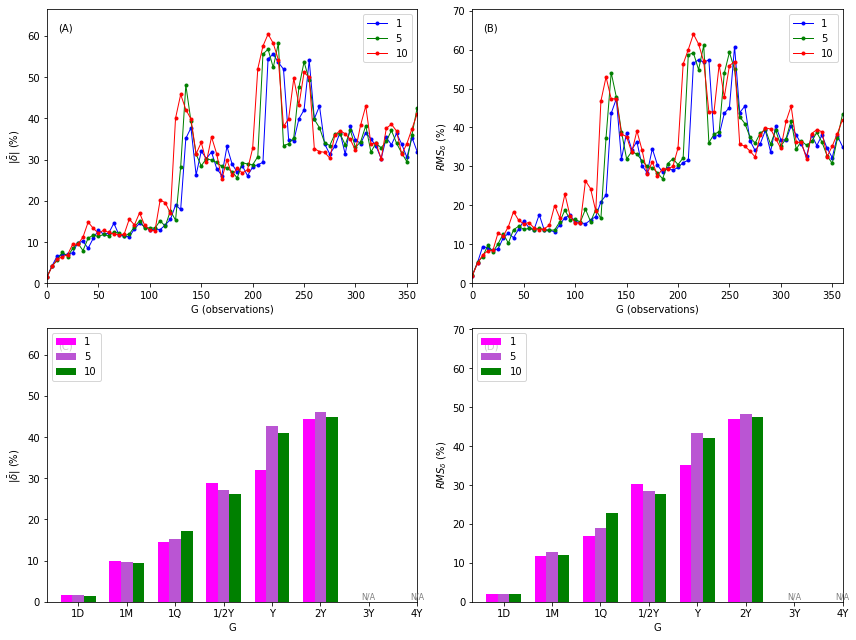

Saved Figure 9 to: liu_replication_outputs/liu_figure9_error_metrics.png
Saved error table and forecast predictions.


In [8]:

import re

# Match your column names, whether they use spaces or underscores
def clean_name(name):
    return re.sub(r"[^a-z0-9]+", " ", str(name).lower()).strip()

aliases = {
    "Copper": ["copper"],
    "Crude_Oil": ["crude oil", "wti", "oil"],
    "Gold": ["gold"],
    "Silver": ["silver"],
    "Natural_Gas": ["natural gas"],
    "Coffee": ["coffee"],
    "Dow_Jones": ["dow jones"],
    "Lean_Hogs": ["lean hogs"]
}

column_map = {}

for variable, names in aliases.items():
    matches = [
        col for col in data.columns
        if any(name in clean_name(col) for name in names)
    ]

    if not matches:
        raise ValueError(
            f"Cannot find {variable}. Available columns: "
            f"{data.columns.tolist()}"
        )

    column_map[variable] = matches[0]

variables = [
    "Crude_Oil", "Copper", "Gold", "Silver",
    "Natural_Gas", "Coffee", "Dow_Jones", "Lean_Hogs"
]

paper_data = data.loc[
    "2008-01-03":"2015-12-01",
    [column_map[v] for v in variables]
].copy()

paper_data.columns = variables
paper_data = paper_data.dropna()

values = paper_data[variables].to_numpy(dtype=float)
copper = paper_data["Copper"].to_numpy(dtype=float)
n = len(paper_data)

print(f"Observations: {n}")
print(
    f"Date range: {paper_data.index.min().date()} "
    f"through {paper_data.index.max().date()}"
)

# --------------------------------------------------
# 2. Set D and G parameters
# --------------------------------------------------

D_VALUES = [1, 5, 10]

# Short-term: G = 0, 15, 30, ..., 360
G_SHORT = list(range(0, 361, 5))

# Long-term horizons
G_LONG = [0, 30, 90, 180, 360, 720, 1080, 1440]

G_VALUES = sorted(set(G_SHORT + G_LONG))

# Require enough historical training examples
MIN_TRAIN = 250

# Refit the model every 50 observations for practicality.
# Set to 1 to refit at every available forecast origin.
ORIGIN_STEP = 1

# Evaluate forecasts near the end of the sample
TEST_WINDOW = 200

# --------------------------------------------------
# 3. Generate rolling forecasts
# --------------------------------------------------

all_predictions = []
all_metrics = []

for D in D_VALUES:

    for G in G_VALUES:

        # Each row predicts copper at target position t
        # from D observations ending G+1 observations earlier.
        target_positions = np.arange(G + D, n)

        X_all = np.array([
            values[t - G - D:t - G].flatten()
            for t in target_positions
        ])

        y_all = copper[target_positions]

        # Last available origin whose future target remains
        # inside the dataset.
        max_origin = n - G - 2

        # Use a final evaluation window of up to 200 origins
        first_origin = max(
            G + D + MIN_TRAIN - 1,
            max_origin - TEST_WINDOW + 1
        )

        origins = np.arange(
            first_origin,
            max_origin + 1,
            ORIGIN_STEP
        )

        errors = []

        # No training examples or no available forecasts
        if len(origins) == 0:
            all_metrics.append({
                "D": D,
                "G": G,
                "MAPE": np.nan,
                "RMS": np.nan,
                "Outliers_over_10_percent": np.nan,
                "N": 0
            })
            continue

        # Refit the model using labeled data available
        # up to each forecast origin.
        for origin in origins:

            train_mask = target_positions <= origin

            X_train = X_all[train_mask]
            y_train = y_all[train_mask]

            if len(y_train) < MIN_TRAIN:
                continue

            # The latest D observations available today
            X_test = values[
                origin - D + 1:origin + 1
            ].flatten().reshape(1, -1)

            # Copper price G+1 observations after today
            target = origin + G + 1
            actual = copper[target]

            model = DecisionTreeRegressor(
                max_depth=23,
                random_state=42
            )

            model.fit(X_train, y_train)
            predicted = model.predict(X_test)[0]

            # Equation (16): relative error, in percent
            delta = (predicted - actual) / actual * 100

            errors.append(delta)

            all_predictions.append({
                "D": D,
                "G": G,
                "ForecastOrigin": paper_data.index[origin],
                "TargetDate": paper_data.index[target],
                "Actual": actual,
                "Prediction": predicted,
                "PercentageError": delta
            })

        # Equations (14) and (15)
        if len(errors) > 0:
            errors = np.array(errors)

            mape = np.mean(np.abs(errors))
            rms = np.sqrt(np.mean(errors ** 2))
            outliers = np.mean(np.abs(errors) > 10) * 100
        else:
            mape = np.nan
            rms = np.nan
            outliers = np.nan

        all_metrics.append({
            "D": D,
            "G": G,
            "MAPE": mape,
            "RMS": rms,
            "Outliers_over_10_percent": outliers,
            "N": len(errors)
        })

    print(f"Finished D={D}")

# --------------------------------------------------
# 4. Display and save error results
# --------------------------------------------------

metrics = pd.DataFrame(all_metrics)

display(metrics.round(3))

metrics.to_csv(
    OUT / "liu_figure9_error_metrics.csv",
    index=False
)

predictions_df = pd.DataFrame(all_predictions)

predictions_df.to_csv(
    OUT / "liu_figure9_rolling_predictions.csv",
    index=False
)

# --------------------------------------------------
# 5. Recreate Figure 9
# --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Short-term line plots
short_colors = {
    1: "blue",
    5: "green",
    10: "red"
}

for D in D_VALUES:

    subset = metrics[
        (metrics["D"] == D) &
        (metrics["G"].isin(G_SHORT))
    ].sort_values("G")

    axes[0, 0].plot(
        subset["G"], subset["MAPE"],
        color=short_colors[D],
        marker="o", markersize=3,
        linewidth=1, label=str(D)
    )

    axes[0, 1].plot(
        subset["G"], subset["RMS"],
        color=short_colors[D],
        marker="o", markersize=3,
        linewidth=1, label=str(D)
    )

axes[0, 0].set_ylabel(r"$|\bar{\delta}|$ (%)")
axes[0, 1].set_ylabel(r"$RMS_{\delta}$ (%)")

for ax in axes[0]:
    ax.set_xlabel("G (observations)")
    ax.set_xlim(0, 360)
    ax.legend(title=None)
    ax.grid(False)

# Long-term grouped bar plots
long_labels = ["1D", "1M", "1Q", "1/2Y",
               "Y", "2Y", "3Y", "4Y"]

x = np.arange(len(G_LONG))
width = 0.24

bar_colors = {
    1: "magenta",
    5: "mediumorchid",
    10: "green"
}

for i, D in enumerate(D_VALUES):

    subset = (
        metrics[metrics["D"] == D]
        .set_index("G")
        .reindex(G_LONG)
    )

    offset = (i - 1) * width

    axes[1, 0].bar(
        x + offset, subset["MAPE"],
        width=width,
        color=bar_colors[D],
        label=str(D)
    )

    axes[1, 1].bar(
        x + offset, subset["RMS"],
        width=width,
        color=bar_colors[D],
        label=str(D)
    )

axes[1, 0].set_ylabel(r"$|\bar{\delta}|$ (%)")
axes[1, 1].set_ylabel(r"$RMS_{\delta}$ (%)")

for ax in axes[1]:
    ax.set_xticks(x)
    ax.set_xticklabels(long_labels)
    ax.set_xlabel("G")
    ax.legend(title=None)
    ax.grid(False)

# Show the unavailable long horizons explicitly
for ax in axes[1]:
    for i, G in enumerate(G_LONG):
        if metrics.loc[metrics["G"] == G, "N"].max() == 0:
            ax.text(
                x[i], 0.15, "N/A",
                ha="center", va="bottom",
                fontsize=8, color="gray"
            )

# Preserve the paper's scales when possible,
# but expand them if needed to show all calculated errors.
mape_max = metrics["MAPE"].max()
rms_max = metrics["RMS"].max()

mape_limit = max(5, mape_max * 1.1) if pd.notna(mape_max) else 5
rms_limit = max(10, rms_max * 1.1) if pd.notna(rms_max) else 10

axes[0, 0].set_ylim(0, mape_limit)
axes[1, 0].set_ylim(0, mape_limit)
axes[0, 1].set_ylim(0, rms_limit)
axes[1, 1].set_ylim(0, rms_limit)

# Panel labels
for ax, letter in zip(
    axes.flat, ["(A)", "(B)", "(C)", "(D)"]
):
    ax.text(
        0.03, 0.95, letter,
        transform=ax.transAxes,
        va="top"
    )

fig.tight_layout()

filename = OUT / "liu_figure9_error_metrics.png"

fig.savefig(
    filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Saved Figure 9 to: {filename}")
print("Saved error table and forecast predictions.")



## 2. Diaz et al. (2020): Regression tree, random forest, gradient boosting

The paper reports data from both **January 3, 2008 through December 1, 2015** and **January 3, 2008 through December 1, 2020** We filter the common-date dataset to that period.

In [9]:
from scipy.stats import pearsonr
from IPython.display import display, Markdown

DOW_SUPPLEMENT = "Dow Jones Industrial Average Historical Data(2).csv"

VARIABLES = list(FILES.keys())
# ------------------------------------------------------------
# 2. Read and clean each CSV
# ------------------------------------------------------------

def read_price_series(filename, variable_name):

    path = Path(filename)

    if not path.exists():
        raise FileNotFoundError(
            f"Cannot find {filename}. "
            "Make sure your existing CSV files are in the notebook folder."
        )

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    if "Date" not in df.columns or "Price" not in df.columns:
        raise ValueError(
            f"{filename} must have columns named Date and Price."
        )

    # Parse dates, accommodating common Investing.com date formats.
    raw_dates = df["Date"].astype(str).str.strip()

    dates = pd.to_datetime(
        raw_dates,
        format="%m/%d/%Y",
        errors="coerce"
    )

    missing_dates = dates.isna()

    if missing_dates.any():
        dates.loc[missing_dates] = pd.to_datetime(
            raw_dates.loc[missing_dates],
            errors="coerce"
        )

    df["Date"] = dates

    # Convert prices to numeric values.
    df[variable_name] = pd.to_numeric(
        df["Price"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False),
        errors="coerce"
    )

    df = df[["Date", variable_name]].dropna()

    # Average any duplicate entries for the same date.
    df = (
        df.groupby("Date", as_index=False)[variable_name]
        .mean()
        .sort_values("Date")
    )

    return df


# ------------------------------------------------------------
# 3. Load all eight variables
# ------------------------------------------------------------

series = []

for variable, filename in FILES.items():

    current = read_price_series(filename, variable)

    # Supplement Dow Jones with the additional file already in your folder.
    if variable == "Dow Jones":

        supplement_path = Path(DOW_SUPPLEMENT)

        if supplement_path.exists():

            supplement = read_price_series(
                DOW_SUPPLEMENT,
                variable
            )

            last_current_date = current["Date"].max()

            supplement = supplement[
                supplement["Date"] > last_current_date
            ]

            current = pd.concat(
                [current, supplement],
                ignore_index=True
            )

            current = (
                current.sort_values("Date")
                .drop_duplicates("Date", keep="last")
            )

    series.append(current)


# ------------------------------------------------------------
# 4. Align dates and create diaz_data
# ------------------------------------------------------------

# Keep dates covered by all eight series.
start_date = max(
    s["Date"].min() for s in series
)

end_date = min(
    s["Date"].max() for s in series
)

# Exclude weekends, consistent with the weekday-based dataset.
weekday_index = pd.bdate_range(
    start=start_date,
    end=end_date,
    name="Date"
)

aligned = {}

for df, variable in zip(series, VARIABLES):

    prices = (
        df.set_index("Date")[variable]
        .sort_index()
    )

    prices = prices.reindex(weekday_index)

    # Interpolate missing weekday values between available prices.
    prices = prices.interpolate(
        method="time",
        limit_area="inside"
    )

    aligned[variable] = prices

# This is your cleaned dataset for the Díaz exercises.
diaz_data = pd.DataFrame(
    aligned,
    index=weekday_index
).dropna()

diaz_data = diaz_data[VARIABLES].sort_index()

print("Cleaned dataset created: diaz_data")
print(f"Observations: {len(diaz_data):,}")
print(f"Available period: {diaz_data.index.min().date()} "
      f"to {diaz_data.index.max().date()}")

display(diaz_data.head())


# ------------------------------------------------------------
# 5. Use the original paper's period for Table 1
# January 2008 through May 2020
# ------------------------------------------------------------

table1_data = diaz_data.loc[
    "2008-01-01":"2020-05-31",
    VARIABLES
].dropna()

if table1_data.empty:
    raise ValueError(
        "No data available for the Table 1 period. "
        "Check the dates in your existing CSV files."
    )

print(
    f"\nTable 1 sample period: "
    f"{table1_data.index.min().date()} to "
    f"{table1_data.index.max().date()}"
)

if table1_data.index.min() > pd.Timestamp("2008-01-01"):
    print(
        "WARNING: Your files do not cover the full period from January 2008."
    )

if table1_data.index.max() < pd.Timestamp("2020-05-31"):
    print(
        "WARNING: Your files do not cover the full period through May 2020."
    )


# ------------------------------------------------------------
# 6. TABLE 1 — PANEL A: DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

table1_panel_a = pd.DataFrame({
    "Mean": table1_data.mean(),
    "Std. Dev.": table1_data.std(),
    "Min": table1_data.min(),
    "Max": table1_data.max()
}).round(2)

table1_panel_a.index.name = "Variable"

display(Markdown("## Table 1. Descriptive Statistics and Correlations"))
display(Markdown("### Panel A: Descriptive Statistics"))

display(
    table1_panel_a.style
    .format("{:.2f}")
    .set_properties(**{"text-align": "right"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "caption", "props": [
            ("caption-side", "top"),
            ("font-size", "14px"),
            ("font-weight", "bold")
        ]}
    ])
)


# ------------------------------------------------------------
# 7. TABLE 1 — PANEL B: CORRELATIONS
# Lower triangle, with * for p < 0.05
# ------------------------------------------------------------

corr_table = pd.DataFrame(
    "",
    index=VARIABLES,
    columns=VARIABLES
)

for i, row in enumerate(VARIABLES):

    for j, col in enumerate(VARIABLES):

        if i == j:
            corr_table.loc[row, col] = "1.00"

        elif j < i:

            r, p = pearsonr(
                table1_data[row],
                table1_data[col]
            )

            star = "*" if p < 0.05 else ""

            corr_table.loc[row, col] = (
                f"{r:.2f}{star}"
            )

corr_table.index.name = "Variable"

display(Markdown("### Panel B: Correlations"))

display(
    corr_table.style
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
    ])
)

display(Markdown(
    "**Notes:** Panel A reports the mean, standard deviation, minimum, "
    "and maximum. Panel B reports Pearson pairwise correlations. "
    "* indicates statistical significance at the 95% confidence level. "
    "The intended sample period is January 2008 through May 2020."
))

Cleaned dataset created: diaz_data
Observations: 4,652
Available period: 2008-01-02 to 2025-10-30


,Copper,Gold,Silver,Oil,Gas,Lean Hogs,Coffee,Dow Jones
Date,,,,,,,,
2008-01-02,3.0640,860.0,15.290,99.62,7.850,57.17,134.00,13043.96
2008-01-03,3.1880,869.1,15.500,99.18,7.674,56.48,135.20,13056.72
2008-01-04,3.1575,865.7,15.462,97.91,7.841,56.40,132.70,12800.18
2008-01-07,3.1410,862.0,15.290,95.09,7.879,55.70,131.40,12827.49
2008-01-08,3.2985,880.3,15.815,96.33,7.967,55.88,135.45,12589.07



Table 1 sample period: 2008-01-02 to 2020-05-29


## Table 1. Descriptive Statistics and Correlations

### Panel A: Descriptive Statistics

,Mean,Std. Dev.,Min,Max
Variable,,,,
Copper,3.00,0.63,1.27,4.63
Gold,1289.76,236.43,705.00,1891.90
Silver,19.97,6.88,8.79,48.60
Oil,72.70,24.06,11.57,145.29
Gas,3.78,1.83,1.64,13.58
Lean Hogs,75.38,16.14,37.33,133.88
Coffee,146.53,42.47,86.65,304.90
Dow Jones,16652.53,5698.55,6547.05,29551.42


### Panel B: Correlations

,Copper,Gold,Silver,Oil,Gas,Lean Hogs,Coffee,Dow Jones
Variable,,,,,,,,
Copper,1.00,,,,,,,
Gold,0.43*,1.00,,,,,,
Silver,0.75*,0.74*,1.00,,,,,
Oil,0.79*,0.13*,0.55*,1.00,,,,
Gas,0.31*,-0.51*,-0.05*,0.58*,1.00,,,
Lean Hogs,0.47*,0.35*,0.48*,0.57*,0.03,1.00,,
Coffee,0.64*,0.40*,0.78*,0.48*,0.10*,0.49*,1.00,
Dow Jones,-0.25*,0.24*,-0.31*,-0.45*,-0.47*,-0.16*,-0.44*,1.00


**Notes:** Panel A reports the mean, standard deviation, minimum, and maximum. Panel B reports Pearson pairwise correlations. * indicates statistical significance at the 95% confidence level. The intended sample period is January 2008 through May 2020.

In [ ]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor


# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

# Practical settings to reduce runtime.
# The paper evaluates every test observation and uses 1,500 RF trees.
ROLLING_STEP = 10
TRAIN_WINDOW = 607
RF_TREES = 100
GBRT_TREES = 100
RANDOM_STATE = 42

HORIZONS = [1, 5, 20, 120, 250, 500]

HORIZON_LABELS = {
    1: "1 day",
    5: "1 week",
    20: "1 month",
    120: "6 months",
    250: "1 year",
    500: "2 years"
}

D_VALUES = [1, 5, 10, 20, 40, 80]

VARIABLES = [
    "Copper",
    "Gold",
    "Silver",
    "Oil",
    "Gas",
    "Lean Hogs",
    "Coffee",
    "Dow Jones"
]

# Confirm diaz_data already exists from your previous cell.
if "diaz_data" not in globals():
    raise NameError(
        "diaz_data was not found. Run your Table 1 data-cleaning cell first."
    )

missing_columns = [
    col for col in VARIABLES if col not in diaz_data.columns
]

if missing_columns:
    raise ValueError(
        f"diaz_data is missing these columns: {missing_columns}"
    )

diaz_data = diaz_data.copy()
diaz_data.index = pd.to_datetime(diaz_data.index)
diaz_data = diaz_data.sort_index()

# Restrict the extended exercise to dates no later than December 2026.
latest_date = min(
    diaz_data.index.max(),
    pd.Timestamp("2026-12-31")
)

print("Using existing diaz_data.")
print(f"Data available: {diaz_data.index.min().date()} "
      f"through {diaz_data.index.max().date()}")


# ------------------------------------------------------------
# 2. DEFINE THE THREE EXERCISES
# ------------------------------------------------------------

EXERCISES = {
    "A": {
        "start": "2008-01-01",
        "end": "2015-12-31",
        "title": "Table 2 — Exercise A",
        "description": "Short sample, 2008:01–2015:12"
    },
    "B": {
        "start": "2008-01-01",
        "end": "2020-05-31",
        "title": "Table 3 — Exercise B",
        "description": "Full sample, 2008:01–2020:05"
    },
    "C": {
        "start": "2008-01-01",
        "end": str(latest_date.date()),
        "title": "Table C — Exercise C",
        "description": (
            f"Extended sample, 2008:01–{latest_date.strftime('%Y:%m')}"
        )
    }
}


# ------------------------------------------------------------
# 3. DEFINE FORECASTING MODELS
# ------------------------------------------------------------

def make_models(n_features):
    """
    Paper-inspired forecasting models.

    Note: RT pruning and GBM tree-count cross-validation are not
    implemented here; fixed settings are used to keep the code practical.
    """

    return {
        "RT": DecisionTreeRegressor(
            max_depth=5,
            min_samples_leaf=5,
            random_state=RANDOM_STATE
        ),

        "RF": RandomForestRegressor(
            n_estimators=RF_TREES,
            max_features=min(8, n_features),
            max_leaf_nodes=5,
            n_jobs=1,
            random_state=RANDOM_STATE
        ),

        "GBM": GradientBoostingRegressor(
            n_estimators=GBRT_TREES,
            learning_rate=0.01,
            max_depth=1,
            random_state=RANDOM_STATE
        )
    }


# ------------------------------------------------------------
# 4. RUN ONE EXERCISE
# ------------------------------------------------------------

def run_exercise(exercise_name, start_date, end_date):

    sample = diaz_data.loc[
        start_date:end_date,
        VARIABLES
    ].dropna().copy()

    if sample.empty:
        raise ValueError(
            f"Exercise {exercise_name} has no observations in "
            f"{start_date} through {end_date}."
        )

    sample_values = sample.to_numpy(dtype=float)
    copper = sample["Copper"].to_numpy(dtype=float)
    n_obs = len(sample)

    print(
        f"\nRunning Exercise {exercise_name}: "
        f"{sample.index.min().date()} to "
        f"{sample.index.max().date()} "
        f"({n_obs:,} observations)"
    )

    records = []

    for D in D_VALUES:

        print(f"  Processing D = {D}...")

        for h in HORIZONS:

            # Target price is observed h rows after the predictor date.
            # Predictors are X_t, X_(t-1), ..., X_(t-D+1).
            target_positions = np.arange(
                h + D - 1,
                n_obs
            )

            metric_columns = {
                f"{metric}_{model}": np.nan
                for metric in ["RMSE", "MAE"]
                for model in ["RT", "RF", "GBM", "RW"]
            }

            # Not enough supervised observations for a 607-observation
            # initial training window.
            if len(target_positions) <= TRAIN_WINDOW:

                records.append({
                    "D": D,
                    "h": h,
                    "Horizon": HORIZON_LABELS[h],
                    "N": 0,
                    **metric_columns
                })

                continue

            # Construct one feature row for each target.
            # Each row consists of D lags of all eight variables.
            X_all = np.asarray([
                sample_values[
                    target - h - D + 1:
                    target - h + 1
                ].reshape(-1)
                for target in target_positions
            ])

            y_all = copper[target_positions]

            # Start testing once 607 supervised target outcomes
            # are available at the forecast origin.
            first_test_target = int(
                target_positions[TRAIN_WINDOW - 1] + h
            )

            test_targets = np.arange(
                first_test_target,
                n_obs,
                ROLLING_STEP
            )

            errors = {
                "RT": [],
                "RF": [],
                "GBM": [],
                "RW": []
            }

            for target in test_targets:

                # Information available at the forecast origin.
                origin = int(target - h)

                # Only include training outcomes observed by the origin.
                train_end = int(
                    np.searchsorted(
                        target_positions,
                        origin,
                        side="right"
                    )
                )

                # Fixed rolling window: the most recent 607 training cases.
                train_start = max(
                    0,
                    train_end - TRAIN_WINDOW
                )

                if train_end - train_start < TRAIN_WINDOW:
                    continue

                X_train = X_all[train_start:train_end]
                y_train = y_all[train_start:train_end]

                # Get the features for this target date.
                test_row = int(
                    target - target_positions[0]
                )

                X_test = X_all[test_row].reshape(1, -1)
                actual = float(copper[target])

                # Fit the three tree-based models.
                models = make_models(X_train.shape[1])

                for model_name, model in models.items():

                    model.fit(X_train, y_train)

                    predicted = float(
                        model.predict(X_test)[0]
                    )

                    # Percentage forecast error.
                    percentage_error = (
                        100.0 * (actual - predicted) / actual
                    )

                    errors[model_name].append(
                        percentage_error
                    )

                # Random walk without drift:
                # the forecast equals the latest observed copper price.
                rw_predicted = float(copper[origin])

                errors["RW"].append(
                    100.0 * (actual - rw_predicted) / actual
                )

            # Calculate percentage RMSE and MAE for this D and h.
            row = {
                "D": D,
                "h": h,
                "Horizon": HORIZON_LABELS[h],
                "N": len(errors["RW"])
            }

            for model_name in ["RT", "RF", "GBM", "RW"]:

                e = np.asarray(
                    errors[model_name],
                    dtype=float
                )

                if len(e) > 0:

                    row[f"RMSE_{model_name}"] = np.sqrt(
                        np.mean(e ** 2)
                    )

                    row[f"MAE_{model_name}"] = np.mean(
                        np.abs(e)
                    )

                else:

                    row[f"RMSE_{model_name}"] = np.nan
                    row[f"MAE_{model_name}"] = np.nan

            records.append(row)

    results = pd.DataFrame(records)

    results = (
        results.sort_values(["D", "h"])
        .reset_index(drop=True)
    )

    results.to_csv(
        OUT / f"exercise_{exercise_name}_results_long.csv",
        index=False
    )

    return results


# ------------------------------------------------------------
# 5. FORMAT RESULTS LIKE THE PAPER'S TABLES
# ------------------------------------------------------------

METRIC_COLUMNS = [
    "RMSE_RT",
    "RMSE_RF",
    "RMSE_GBM",
    "RMSE_RW",
    "MAE_RT",
    "MAE_RF",
    "MAE_GBM",
    "MAE_RW"
]

PAPER_COLUMNS = pd.MultiIndex.from_tuples([
    ("RMSE (%)", "RT"),
    ("RMSE (%)", "RF"),
    ("RMSE (%)", "GBM"),
    ("RMSE (%)", "RW"),
    ("MAE (%)", "RT"),
    ("MAE (%)", "RF"),
    ("MAE (%)", "GBM"),
    ("MAE (%)", "RW")
])


def make_paper_table(results):

    table = results.set_index(
        ["D", "Horizon"]
    )[METRIC_COLUMNS].copy()

    table.columns = PAPER_COLUMNS

    return table


# ------------------------------------------------------------
# 6. RUN A, B, AND C AND DISPLAY EACH TABLE
# ------------------------------------------------------------

all_results = {}
all_tables = {}

for exercise_name, settings in EXERCISES.items():

    result = run_exercise(
        exercise_name,
        settings["start"],
        settings["end"]
    )

    all_results[exercise_name] = result

    paper_table = make_paper_table(result)
    all_tables[exercise_name] = paper_table

    # Save the complete wide-format table.
    if exercise_name == "A":
        filename = "table2_exercise_A.csv"

    elif exercise_name == "B":
        filename = "table3_exercise_B.csv"

    else:
        filename = "tableC_exercise_C_through_2026.csv"

    paper_table.to_csv(OUT / filename)

    # Display one D block at a time, matching the paper's layout.
    display(Markdown(
        f"## {settings['title']}\n"
        f"*{settings['description']}*"
    ))

    for D in D_VALUES:

        subset = (
            result[result["D"] == D]
            .sort_values("h")
            .set_index("Horizon")[METRIC_COLUMNS]
            .copy()
        )

        subset.columns = PAPER_COLUMNS

        display(Markdown(f"**D = {D}**"))

        display(
            subset.style
            .format("{:.2f}", na_rep="—")
            .set_properties(**{"text-align": "center"})
            .set_table_styles([
                {
                    "selector": "th",
                    "props": [("text-align", "center")]
                }
            ])
        )


# ------------------------------------------------------------
# 7. SAVE ALL EXERCISES TOGETHER
# ------------------------------------------------------------

combined_results = pd.concat(
    [
        results.assign(Exercise=exercise_name)
        for exercise_name, results in all_results.items()
    ],
    ignore_index=True
)

combined_results.to_csv(
    OUT / "tables_A_B_C_combined.csv",
    index=False
)

print("\nFinished generating Tables 2, 3, and C.")
print(f"Latest date available in diaz_data: {diaz_data.index.max().date()}")
print(f"Exercise C ends: {latest_date.date()}")
print(f"Output folder: {OUT.resolve()}")
print(f"Rolling forecast step: {ROLLING_STEP}")

Using existing diaz_data.
Data available: 2008-01-02 through 2025-10-30

Running Exercise A: 2008-01-02 to 2015-12-31 (2,087 observations)
  Processing D = 1...
  Processing D = 5...
  Processing D = 10...
  Processing D = 20...


In [ ]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Keep the eight market variables in chronological order.
base = diaz_data[VARIABLES].copy().sort_index()

base = base.apply(pd.to_numeric, errors="coerce")

# Use current values and selected historical lags as predictors.
# lag0 = current observation, known at the forecast origin.
LAGS = [0, 1, 2, 3, 5, 10]

price_model_data = pd.DataFrame(index=base.index)
price_features = []

# Create lagged predictors for all eight market variables.
for variable in VARIABLES:

    safe_name = variable.replace(" ", "_")

    for lag in LAGS:

        feature_name = f"{safe_name}_lag{lag}"

        price_model_data[feature_name] = base[variable].shift(lag)

        price_features.append(feature_name)

# Target is copper's price at the NEXT observation.
price_model_data["CopperPrice"] = base["Copper"].shift(-1)

# Date corresponds to the date of the target price.
price_model_data["Date"] = pd.Series(
    base.index,
    index=base.index
).shift(-1)

# Remove rows with missing predictors or target values.
price_model_data = (
    price_model_data
    .dropna(subset=["Date", "CopperPrice"] + price_features)
    .sort_values("Date")
    .reset_index(drop=True)
)

print("price_model_data created successfully.")
print(f"Observations: {len(price_model_data):,}")
print(f"Number of predictors: {len(price_features)}")
print(f"Date range: {price_model_data['Date'].min().date()} "
      f"to {price_model_data['Date'].max().date()}")

print("\nPredictor columns:")
print(price_features)

display(price_model_data.head())

# Prepare the monthly price data
tune_data = (
    price_model_data
    .dropna(subset=["CopperPrice"] + price_features)
    .sort_values("Date")
    .reset_index(drop=True)
)

X = tune_data[price_features]
y = tune_data["CopperPrice"]
dates = tune_data["Date"]

# Use the first 80% for training and the final 20% for testing
split = int(len(tune_data) * 0.80)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
test_dates = dates.iloc[split:]

# Time-ordered cross-validation
tscv = TimeSeriesSplit(n_splits=3)

# Random Forest hyperparameters
rf_grid = {
    "n_estimators": [100, 300],
    "max_depth": [3, 6, None],
    "min_samples_leaf": [1, 3, 5]
}

# Gradient Boosting hyperparameters
gb_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 3]
}

# Find the best Random Forest configuration
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE),
    param_grid=rf_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

# Find the best Gradient Boosting configuration
gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid=gb_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)
gb_search.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best Gradient Boosting parameters:", gb_search.best_params_)

print("Best RF cross-validation MAE:", round(-rf_search.best_score_, 4))
print("Best GB cross-validation MAE:", round(-gb_search.best_score_, 4))

In [ ]:
# Generate predictions on the held-out test set
test_predictions = {
    "Random Forest": rf_search.best_estimator_.predict(X_test),

    "Gradient Boosting": gb_search.best_estimator_.predict(X_test),

    "Random Walk":
        tune_data["CopperPrice"].shift(1).iloc[split:].to_numpy()
}

# Calculate regression metrics
metric_rows = []

for model_name, y_pred in test_predictions.items():
    metric_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

tuned_results = (
    pd.DataFrame(metric_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(tuned_results.round(4))

# Plot actual versus predicted prices
plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    y_test.to_numpy(),
    label="Actual copper price",
    color="black",
    linewidth=2
)

for model_name, y_pred in test_predictions.items():
    plt.plot(
        test_dates,
        y_pred,
        label=model_name,
        alpha=0.85
    )

plt.title("Copper Price Models")
plt.xlabel("Date")
plt.ylabel("Copper price (USD per metric ton)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Output summary and interpretation notes

**1. What does the data look like / any challenges with cleaning up or organizing the data. If you are generating the data - a quick summary or demo of your simulations.**
data directly downloaded from investment.com

**2. What algorithms are suitable and what are the hyperparameters you need to tune.**
Currently, random walk, random forest, gradient boosting, and regression trees were used. Potentially may add KNN. Need to tune D and G. Same with n_estimators, max_depth, min_samples_leaf, learning rate for each model.

**3. What is the success criteria in terms of estimated variables (MSE / R2score or Classification metrics ROC-AUC / F1 score etc.)**
Success criteria measured with MSE, MAE, and R2 Score.

**4. What specific help you need or things you need to figure out moving forward for your own project.**
Will need to download lithium specific data next. might need help knowing if this in going in the right direction or if i will need to pivot algorithms.